# Telangana Ration Shop Clustering Project

Project title: Telangana PDS Analytics - Shop Performance Clustering and Anomaly Profiling

The Telangana Civil Supplies Department runs about 17,000 Fair Price Shops (FPS) that give ration (rice and other items).
It is difficult to check so many shops by hand. In this project I:

1. combine three open datasets (transactions, ration card status, shop locations) for 2023 to 2025,
2. explore the data (EDA),
3. create new features for every shop,
4. group the shops into a few behaviour types with **PCA + K-Means**,
5. find shops that do not fit any group with **DBSCAN**,
6. show the results in a Streamlit dashboard (`app.py`).

**Business use cases:** policy impact of "One Nation One Ration Card" (portability), fraud (shops that are different from similar shops) and logistics (shops with many outside customers).

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# folders used in this project
for folder in ["data/processed", "charts", "reports"]:
    os.makedirs(folder, exist_ok=True)

YEARS = [2023, 2024, 2025]
# the data has no urban/rural column, so I took the Greater Hyderabad districts as urban (my assumption)
URBAN_DISTRICTS = ["Hyderabad", "Medchal", "Ranga Reddy"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Step 1 - Loading the data
The portal gives one CSV file for every month. I use a loop: for each year I read all the monthly files and stack them into a yearly table, and then I stack the three yearly tables into one master table.

In [2]:
def get_year(path):
    """Find the year in a file name, e.g. 01-01-2023_to_31-01-2023.csv gives 2023"""
    return int(re.findall(r"(20\d\d)", os.path.basename(path))[-1])


def load_folder(folder):
    yearly_tables = []
    for year in YEARS:
        files = [f for f in sorted(glob.glob("data/raw/" + folder + "/*.csv")) if get_year(f) == year]
        monthly_tables = [pd.read_csv(f) for f in files]
        yearly = pd.concat(monthly_tables)
        print(folder, year, "->", len(files), "files,", len(yearly), "rows")
        yearly_tables.append(yearly)
    return pd.concat(yearly_tables, ignore_index=True)


transactions = load_folder("transactions")
card_status = load_folder("card_status")
locations = pd.read_csv(glob.glob("data/raw/locations/*.csv")[0])
print()
print("Master tables:", transactions.shape, card_status.shape, locations.shape)
transactions.head(3)

transactions 2023 -> 12 files, 206479 rows


transactions 2024 -> 12 files, 206950 rows


transactions 2025 -> 5 files, 86219 rows


card_status 2023 -> 12 files, 206821 rows


card_status 2024 -> 12 files, 207107 rows


card_status 2025 -> 6 files, 103588 rows

Master tables: (499648, 19) (517516, 28) (17434, 11)


,distCode,distName,officeCode,officeName,shopNo,month,year,noOfRcs,noOfTrans,riceAfsc,riceFsc,riceAap,wheat,sugar,rgdal,kerosene,totalAmount,salt,otherShopTransCnt
0,532,Adilabad,532001,Talamadugu,1901001,1,2023,973,973,1365.0,14725.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32
1,532,Adilabad,532001,Talamadugu,1901002,1,2023,519,519,665.0,8150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25
2,532,Adilabad,532001,Talamadugu,1901003,1,2023,255,255,490.0,3990.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15


In [3]:
# checking the data
KEYS = ["shopNo", "distCode", "month", "year"]
print("Duplicate shop-months in transactions:", transactions.duplicated(KEYS).sum())
print("Duplicate shop-months in card status:", card_status.duplicated(KEYS).sum())
print("Missing values in transactions:", transactions.isna().sum().sum())
print("Columns that are completely empty in card status:", [c for c in card_status.columns if card_status[c].isna().all()])

# Telangana lies roughly between these coordinates, anything else is a wrong GPS value
bad_gps = locations["latitude"].isna() | ~locations["latitude"].between(15.5, 19.95) | ~locations["longitude"].between(77, 81.9)
print("Shops with missing or wrong GPS:", bad_gps.sum(), "out of", len(locations))

Duplicate shop-months in transactions: 0


Duplicate shop-months in card status: 0
Missing values in transactions: 0
Columns that are completely empty in card status: ['cardTypeId', 'mroAsoApprDate', 'cardPoolType']
Shops with missing or wrong GPS: 445 out of 17434


## Step 2 - Joining the 3 tables
I join the three tables into one:
* transactions + card status on `shopNo`, `distCode`, **and also `month` and `year`**, because every shop appears once in every month (without month and year the rows would multiply),
* then + locations on `shopNo` and `distCode`.

In [4]:
joined = transactions.merge(card_status[KEYS + ["totalRcs"]], on=KEYS, how="inner")
master = joined.merge(locations[["shopNo", "distCode", "latitude", "longitude"]], on=["shopNo", "distCode"], how="left")

print("Transaction rows:", len(transactions), "-> after the join:", len(master))
print("Rows lost because the card status was missing:", len(transactions) - len(joined))

# new columns I need later
master["date"] = pd.to_datetime(dict(year=master["year"], month=master["month"], day=1))
master["rice_total"] = master["riceAfsc"] + master["riceFsc"] + master["riceAap"]
master["district_type"] = np.where(master["distName"].isin(URBAN_DISTRICTS), "Urban", "Rural")
master["gps_ok"] = master["latitude"].between(15.5, 19.95) & master["longitude"].between(77, 81.9)
master.head(3)

Transaction rows: 499648 -> after the join: 499494
Rows lost because the card status was missing: 154


,distCode,distName,officeCode,officeName,shopNo,month,year,noOfRcs,noOfTrans,riceAfsc,riceFsc,riceAap,wheat,sugar,rgdal,kerosene,totalAmount,salt,otherShopTransCnt,totalRcs,latitude,longitude,date,rice_total,district_type,gps_ok
0,532,Adilabad,532001,Talamadugu,1901001,1,2023,973,973,1365.0,14725.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32,1108,19.641643,78.391212,2023-01-01,16090.0,Rural,True
1,532,Adilabad,532001,Talamadugu,1901002,1,2023,519,519,665.0,8150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25,584,19.669093,78.422012,2023-01-01,8815.0,Rural,True
2,532,Adilabad,532001,Talamadugu,1901003,1,2023,255,255,490.0,3990.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,293,19.664645,78.427186,2023-01-01,4480.0,Rural,True


## Step 3 - EDA

### 3.1 Growth of other shop transactions (portability)
`otherShopTransCnt` counts transactions of people who took their ration from a shop that is not their own shop.

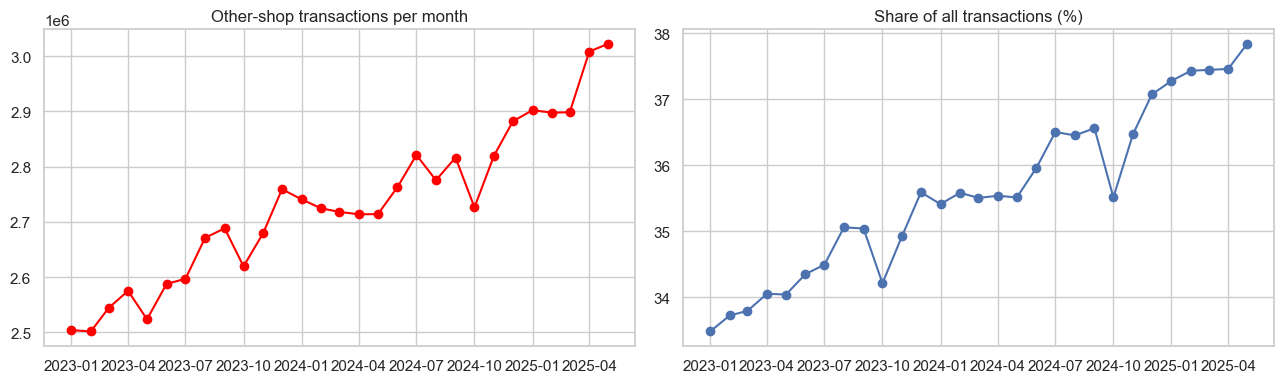

,otherShopTransCnt,noOfTrans,share_%
year,,,
2023,12648218,37403211,33.8
2024,13611178,38333074,35.5
2025,14729186,39285957,37.5


In [5]:
monthly = master.groupby("date").agg(other=("otherShopTransCnt", "sum"), total=("noOfTrans", "sum"))
monthly["share"] = 100 * monthly["other"] / monthly["total"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(monthly.index, monthly["other"], marker="o", color="red")
ax[0].set_title("Other-shop transactions per month")
ax[1].plot(monthly.index, monthly["share"], marker="o")
ax[1].set_title("Share of all transactions (%)")
plt.tight_layout()
plt.savefig("charts/eda_portability_trend.png", dpi=120)
plt.show()

# 2025 only has 5 months, so I compare January to May of every year
same = master[master["month"] <= 5].groupby("year")[["otherShopTransCnt", "noOfTrans"]].sum()
same["share_%"] = (100 * same["otherShopTransCnt"] / same["noOfTrans"]).round(1)
same

**What I see:** portability keeps growing. In January to May it was 33.8% of all transactions in 2023, 35.5% in 2024 and 37.5% in 2025. The monthly volume went from about 2.5 million (Jan 2023) to 3.0 million (May 2025). More and more people use shops that are not their home shop.

### 3.2 Cards (`totalRcs`) vs transactions (`noOfTrans`)

Correlation between cards and transactions: 0.88
Average utilization: 0.837
Shop-months with more transactions than cards: 10.4 %


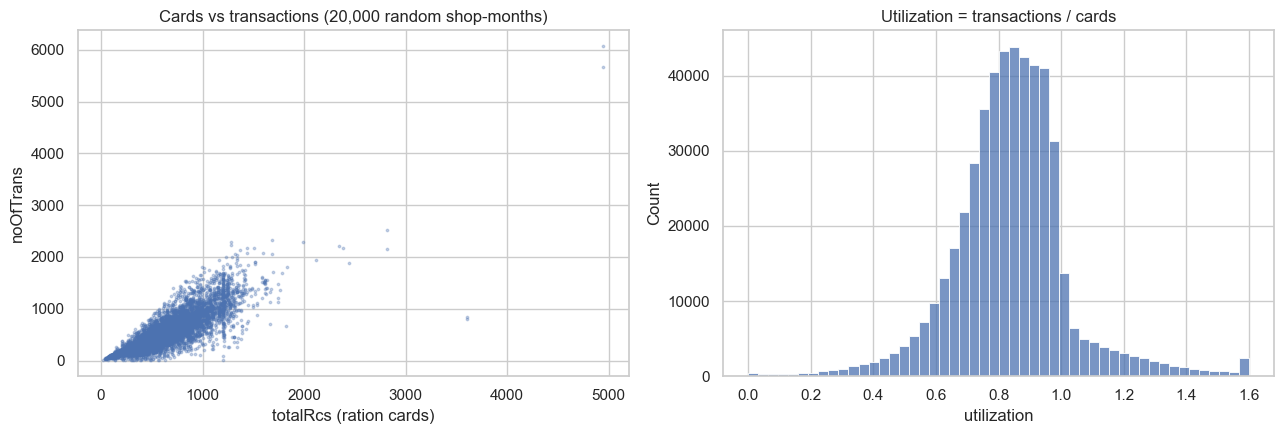

In [6]:
corr = master["totalRcs"].corr(master["noOfTrans"])
master["utilization"] = master["noOfTrans"] / master["totalRcs"]
print("Correlation between cards and transactions:", round(corr, 3))
print("Average utilization:", round(master["utilization"].mean(), 3))
print("Shop-months with more transactions than cards:", round((master["utilization"] > 1).mean() * 100, 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sample = master.sample(20000, random_state=42)
ax[0].scatter(sample["totalRcs"], sample["noOfTrans"], s=3, alpha=0.3)
ax[0].set_xlabel("totalRcs (ration cards)"); ax[0].set_ylabel("noOfTrans")
ax[0].set_title("Cards vs transactions (20,000 random shop-months)")
sns.histplot(master["utilization"].clip(upper=1.6), bins=50, ax=ax[1])
ax[1].set_title("Utilization = transactions / cards")
plt.tight_layout()
plt.savefig("charts/eda_cards_vs_transactions.png", dpi=120)
plt.show()

**What I see:** more cards means more transactions (correlation 0.88). On average a shop serves about 84% of its cards in a month, and 10% of the shop-months have more transactions than cards. Because the card count explains most of the size, the **ratio** (utilization) is more useful than the raw count for comparing shops.

### 3.3 Rice and wheat in the districts

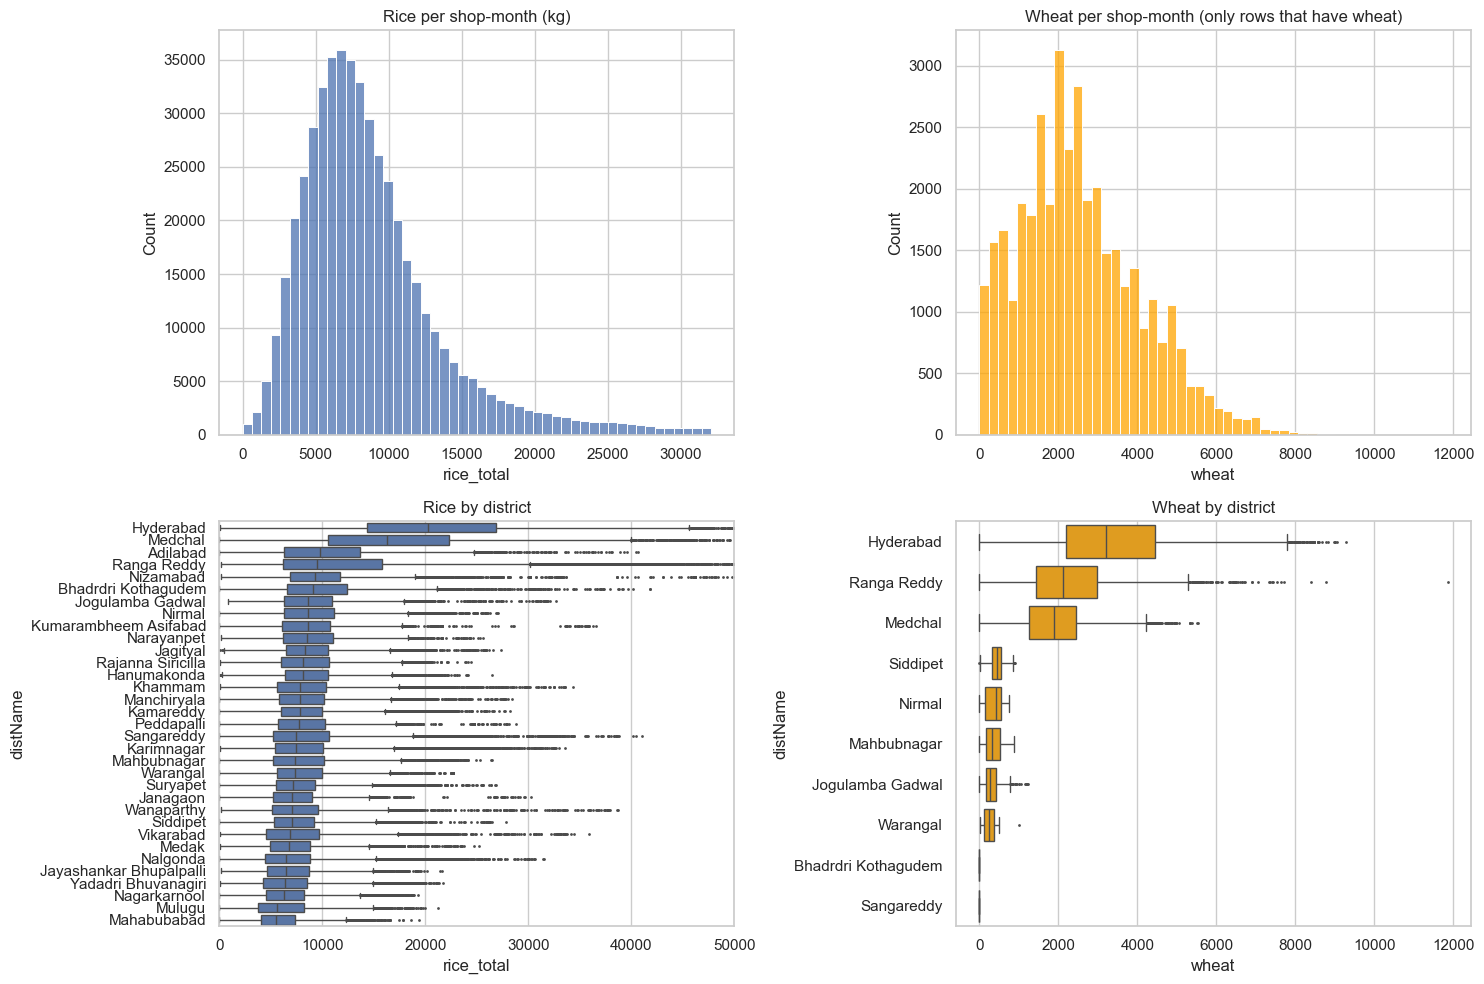

Share of shop-months that have wheat: 7.6 %
Median rice per shop-month: 7810.0 kg
distName
Hyderabad           100.0
Medchal              66.0
Ranga Reddy          19.0
Jogulamba Gadwal      6.0
Name: wheat, dtype: float64


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

rice_limit = master["rice_total"].quantile(0.99)     # cut the top 1% so the chart is readable
sns.histplot(master.loc[master["rice_total"] <= rice_limit, "rice_total"], bins=50, ax=ax[0, 0])
ax[0, 0].set_title("Rice per shop-month (kg)")

wheat_rows = master[master["wheat"] > 0]
sns.histplot(wheat_rows["wheat"], bins=50, ax=ax[0, 1], color="orange")
ax[0, 1].set_title("Wheat per shop-month (only rows that have wheat)")

order = master.groupby("distName")["rice_total"].median().sort_values(ascending=False).index
sns.boxplot(data=master, y="distName", x="rice_total", order=order, ax=ax[1, 0], fliersize=1)
ax[1, 0].set_xlim(0, 50000); ax[1, 0].set_title("Rice by district")

wheat_order = wheat_rows.groupby("distName")["wheat"].median().sort_values(ascending=False).index
sns.boxplot(data=wheat_rows, y="distName", x="wheat", order=wheat_order, ax=ax[1, 1], fliersize=1, color="orange")
ax[1, 1].set_title("Wheat by district")
plt.tight_layout()
plt.savefig("charts/eda_rice_wheat_distribution.png", dpi=120)
plt.show()

print("Share of shop-months that have wheat:", round((master["wheat"] > 0).mean() * 100, 1), "%")
print("Median rice per shop-month:", master["rice_total"].median(), "kg")
print((master.groupby("distName")["wheat"].apply(lambda s: (s > 0).mean() * 100)).sort_values(ascending=False).head(4).round(0))

**What I see:** rice is given in every district (median 7,810 kg per shop per month) and Hyderabad and Medchal have the largest shops. Wheat is rare: only 7.6% of shop-months have wheat and almost all of them are in Hyderabad, Medchal and Ranga Reddy. So wheat is a marker for a small group of shops.

### 3.4 Are some months busier?
For every year I divide each month's transactions by the average month of that year. A value of 1.02 means 2% above a normal month.

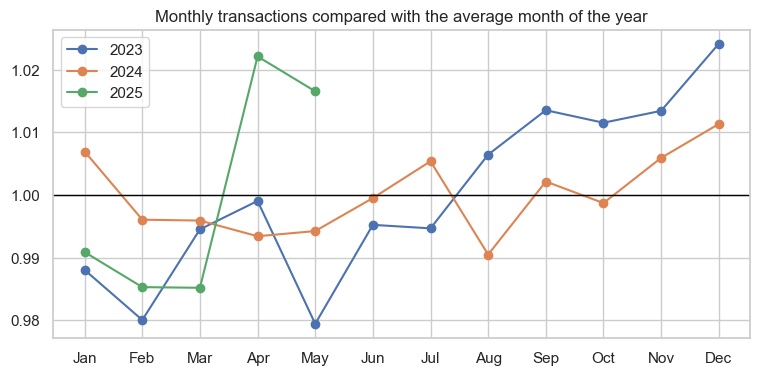

month
12    1.018
11    1.010
9     1.008
dtype: float64

In [8]:
season = master.groupby(["year", "month"])["noOfTrans"].sum().unstack(0)
season_index = season / season.mean()

plt.figure(figsize=(9, 4))
for year in season_index.columns:
    plt.plot(season_index.index, season_index[year], marker="o", label=str(year))
plt.axhline(1, color="black", linewidth=1)
plt.xticks(range(1, 13), MONTHS)
plt.title("Monthly transactions compared with the average month of the year")
plt.legend()
plt.savefig("charts/eda_seasonality.png", dpi=120)
plt.show()
season_index.mean(axis=1).round(3).sort_values(ascending=False).head(3)

**What I see:** the months are very similar. The busiest are December (1.02) and November (1.01), and the lowest is February (0.99), so there is no strong festival or harvest spike in these numbers. (2025 only has January to May.)

## Step 4 - Making new features
For clustering I need **one row per shop**, so I summarise the months of every shop. Shops with fewer than 12 months of data are dropped because their averages are not reliable.

| Feature | Meaning |
|---|---|
| `avg_cards` | average number of ration cards (shop size) |
| `avg_transactions` | average transactions per month |
| `utilization_ratio` | total transactions / total cards |
| `portability_share` | other-shop transactions / all transactions |
| `rice_per_card` | rice (kg) per card |
| `wheat_share` | wheat / (rice + wheat), the commodity mix |
| `volatility_monthly` | standard deviation / mean of the monthly transactions |
| `volatility_yearly` | standard deviation / mean of the yearly average transactions (2023, 2024, 2025) |

In [9]:
shop = master.groupby(["distCode", "shopNo"]).agg(
    distName=("distName", "first"), officeName=("officeName", "first"), district_type=("district_type", "first"),
    latitude=("latitude", "first"), longitude=("longitude", "first"), gps_ok=("gps_ok", "first"),
    months=("month", "size"),
    avg_cards=("totalRcs", "mean"), avg_transactions=("noOfTrans", "mean"), trans_std=("noOfTrans", "std"),
    total_trans=("noOfTrans", "sum"), total_cards=("totalRcs", "sum"), total_other=("otherShopTransCnt", "sum"),
    total_rice=("rice_total", "sum"), total_wheat=("wheat", "sum"))

shop = shop[shop["months"] >= 12].copy()
print("Shops used:", len(shop))

shop["utilization_ratio"] = shop["total_trans"] / shop["total_cards"]
shop["portability_share"] = shop["total_other"] / shop["total_trans"]
shop["rice_per_card"] = shop["total_rice"] / shop["total_cards"]
shop["wheat_share"] = shop["total_wheat"] / (shop["total_rice"] + shop["total_wheat"])
shop["volatility_monthly"] = shop["trans_std"] / shop["avg_transactions"]

# volatility over the years = std of the yearly averages / their mean
yearly_avg = master.groupby(["distCode", "shopNo", "year"])["noOfTrans"].mean().unstack()
shop["volatility_yearly"] = yearly_avg.std(axis=1) / yearly_avg.mean(axis=1)

FEATURES = ["avg_cards", "avg_transactions", "utilization_ratio", "portability_share",
            "rice_per_card", "wheat_share", "volatility_monthly", "volatility_yearly"]
print("Missing values:", shop[FEATURES].isna().sum().sum())
shop[FEATURES] = shop[FEATURES].fillna(shop[FEATURES].median())    # fill the few missing values with the median
shop[FEATURES].describe().round(3)

Shops used: 17335
Missing values: 64


,avg_cards,avg_transactions,utilization_ratio,portability_share,rice_per_card,wheat_share,volatility_monthly,volatility_yearly
count,17335.000,17335.000,17335.000,17335.000,17335.000,17335.000,17335.000,17335.000
mean,522.271,444.965,0.837,0.283,17.087,0.009,0.077,0.046
std,249.853,265.777,0.174,0.272,4.118,0.032,0.090,0.067
min,18.000,8.000,0.028,0.000,0.734,0.000,0.001,0.000
25%,359.716,277.638,0.743,0.058,14.563,0.000,0.030,0.013
50%,483.069,390.483,0.837,0.162,16.740,0.000,0.051,0.026
75%,631.069,538.241,0.924,0.481,19.121,0.000,0.090,0.054
max,4969.655,5746.586,1.871,1.000,40.536,0.520,2.051,1.543


### 4.1 Choosing the features for clustering
K-Means and DBSCAN use distances. If two features say almost the same thing, that idea is counted twice. So I check the correlation between the features first.

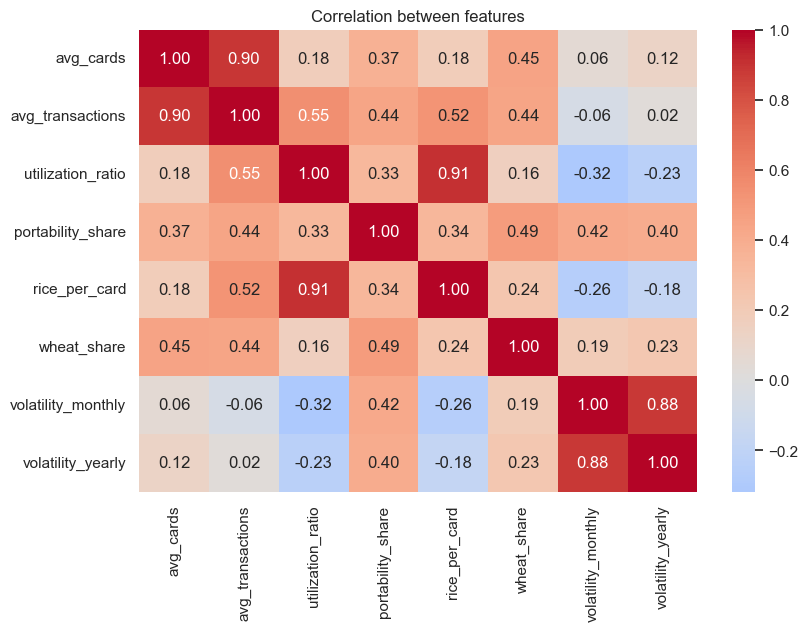

In [10]:
plt.figure(figsize=(9, 6))
sns.heatmap(shop[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between features")
plt.savefig("charts/features_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

Pairs with a correlation above 0.8: `avg_cards` and `avg_transactions` (0.90), `utilization_ratio` and `rice_per_card` (0.91), `volatility_monthly` and `volatility_yearly` (0.88). From every pair I keep one, so the final clustering uses these **5 features**:

| Feature | Why |
|---|---|
| `avg_cards` | shop size (small village shop or big urban shop) |
| `utilization_ratio` | how much of its entitlement the shop really serves, the main fraud signal |
| `portability_share` | how many customers come from other shops (hubs) |
| `wheat_share` | wheat is given only by a small group of shops |
| `volatility_monthly` | how stable the shop is |

The other three features are not used for clustering, but they are still shown in the cluster profiles.

## Step 5 - Scaling and PCA
Features with big numbers (like cards) would dominate features with small numbers (like ratios), so I use `StandardScaler` before any distance-based model. `avg_cards` and `portability_share` are very skewed, so I take the log of them first.
PCA reduces the 5 features to 2 or 3 components so the shops can be drawn on a chart.

In [11]:
CLUSTER_FEATURES = ["avg_cards", "utilization_ratio", "portability_share", "wheat_share", "volatility_monthly"]

X = shop[CLUSTER_FEATURES].copy()
X["avg_cards"] = np.log1p(X["avg_cards"])
X["portability_share"] = np.log1p(100 * X["portability_share"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=3, random_state=42)
pcs = pca.fit_transform(X_scaled)
shop["PC1"], shop["PC2"], shop["PC3"] = pcs[:, 0], pcs[:, 1], pcs[:, 2]
print("Variance explained by PC1, PC2, PC3:", pca.explained_variance_ratio_.round(3))
print("PC1 + PC2:", round(pca.explained_variance_ratio_[:2].sum(), 3), "  PC1 + PC2 + PC3:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by PC1, PC2, PC3: [0.383 0.267 0.162]
PC1 + PC2: 0.65   PC1 + PC2 + PC3: 0.812


**What I see:** two components keep about 65% of the information and three keep about 81%. I only use PCA to draw the clusters; the clustering itself uses all 5 scaled features.

## Step 6 - K-Means
* **Elbow curve:** inertia always goes down when k grows. The "elbow" is where more clusters stop helping much.
* **Silhouette score:** from -1 to 1. A higher value means the shops are close to their own cluster and far from the other clusters.

The project asks for 4 to 5 personas, so I choose the better k in that range.

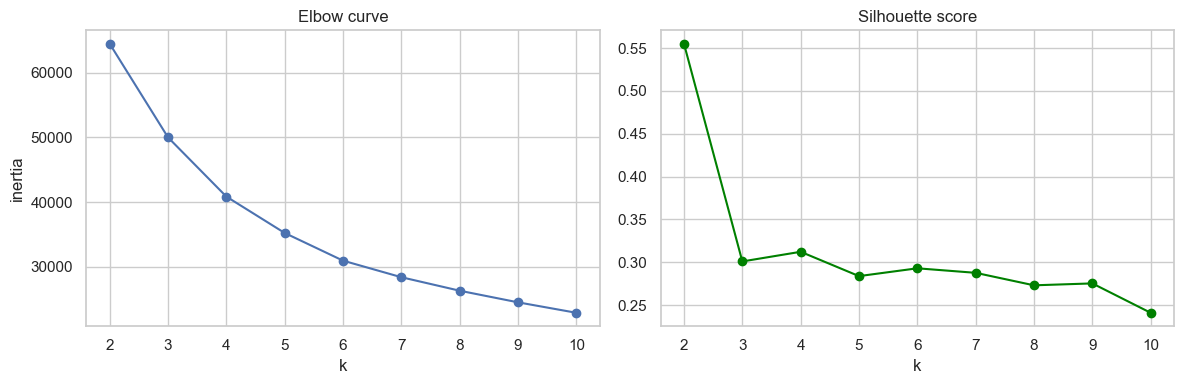

,2,3,4,5,6,7,8,9,10
inertia,64476.274,50012.637,40869.730,35251.002,30975.027,28415.754,26331.135,24537.099,22920.705
silhouette,0.555,0.301,0.312,0.284,0.293,0.288,0.273,0.275,0.241


In [12]:
inertia, silhouette = {}, {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia[k] = model.inertia_
    silhouette[k] = silhouette_score(X_scaled, model.labels_, sample_size=10000, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(inertia.keys()), list(inertia.values()), marker="o")
ax[0].set_title("Elbow curve"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(list(silhouette.keys()), list(silhouette.values()), marker="o", color="green")
ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("charts/kmeans_elbow_silhouette.png", dpi=120)
plt.show()
pd.DataFrame({"inertia": inertia, "silhouette": silhouette}).round(3).T

**What I see:** the elbow curve bends around k = 4 to 5. Between 4 and 5 the silhouette is higher for **k = 4** (0.312 against 0.284), so I use 4 clusters. The score of 0.31 is modest because shops change gradually and do not form separate islands. (k = 2 has the highest score, 0.555, but it only separates the few wheat shops from the rest, which is not useful.)

Silhouette score: 0.312
cluster
0    6479
1    1188
2    8829
3     839
Name: count, dtype: int64


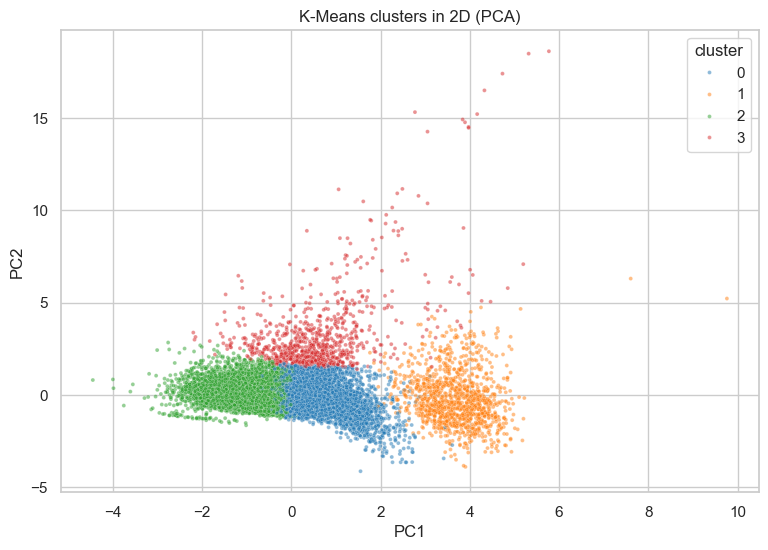

In [13]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X_scaled)
shop["cluster"] = kmeans.labels_
print("Silhouette score:", round(silhouette_score(X_scaled, kmeans.labels_, sample_size=10000, random_state=42), 3))
print(shop["cluster"].value_counts().sort_index())

plt.figure(figsize=(9, 6))
sns.scatterplot(data=shop, x="PC1", y="PC2", hue="cluster", palette="tab10", s=8, alpha=0.5)
plt.title("K-Means clusters in 2D (PCA)")
plt.savefig("charts/kmeans_pca_clusters.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 7 - DBSCAN (finding the odd shops)
DBSCAN does not put every shop in a group. A shop that has fewer than `min_samples` neighbours within the distance `eps` is labelled **noise** (-1). These noise shops are the unusual ones.
* `min_samples = 12`.
* `eps` is chosen from the **k-distance plot**: for every shop I take the distance to its 12th nearest neighbour and sort them. The curve is flat for normal shops and shoots up for isolated shops. I set `eps` at the 98th percentile, where the curve starts to rise.

eps = 1.19   noise shops: 185 ( 1.1 % )


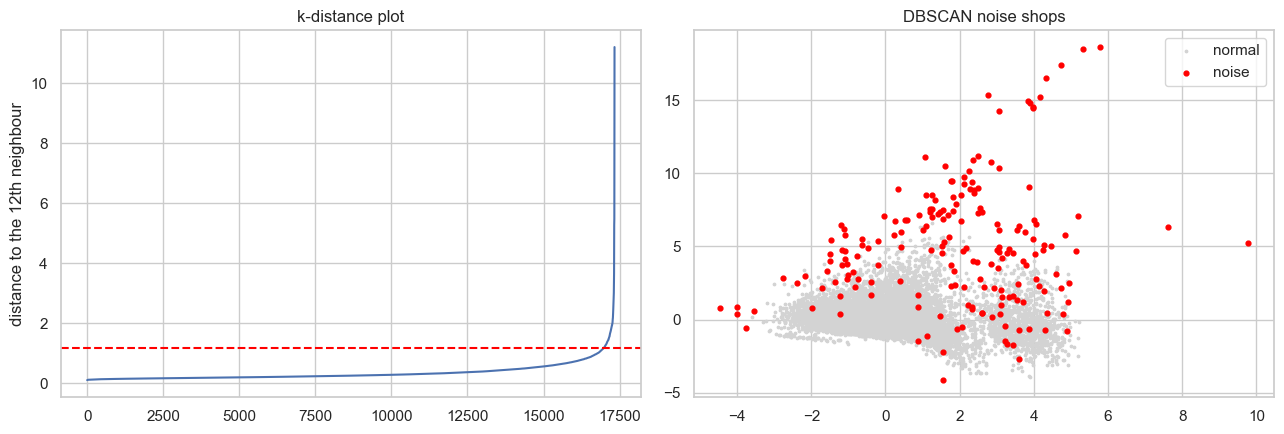

,avg_cards,utilization_ratio,portability_share,wheat_share,volatility_monthly
is_noise,,,,,
False,522.177,0.840,0.280,0.008,0.071
True,530.984,0.569,0.644,0.047,0.546


In [14]:
MIN_SAMPLES = 12
distances = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
distances = np.sort(distances)
eps = np.percentile(distances, 98)

dbscan = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X_scaled)
shop["is_noise"] = dbscan.labels_ == -1
print("eps =", round(eps, 2), "  noise shops:", shop["is_noise"].sum(), "(", round(shop["is_noise"].mean() * 100, 1), "% )")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(distances)
ax[0].axhline(eps, color="red", linestyle="--")
ax[0].set_title("k-distance plot"); ax[0].set_ylabel("distance to the 12th neighbour")
ax[1].scatter(shop.loc[~shop["is_noise"], "PC1"], shop.loc[~shop["is_noise"], "PC2"], s=3, color="lightgrey", label="normal")
ax[1].scatter(shop.loc[shop["is_noise"], "PC1"], shop.loc[shop["is_noise"], "PC2"], s=12, color="red", label="noise")
ax[1].set_title("DBSCAN noise shops"); ax[1].legend()
plt.tight_layout()
plt.savefig("charts/dbscan_noise.png", dpi=120)
plt.show()

shop.groupby("is_noise")[CLUSTER_FEATURES].mean().round(3)

**What I see:** DBSCAN marks 185 shops (1.1%) as noise. Compared with normal shops they have a much lower utilization (0.57 against 0.84), much more portability (0.64 against 0.28) and a far more unstable monthly activity (0.55 against 0.07). These are the first shops to check on the ground.

## Step 8 - Understanding the clusters
For every cluster I calculate the **mean of all features**. Then I give every cluster a name based on what stands out.

In [15]:
profile = shop.groupby("cluster")[FEATURES].mean()
profile["n_shops"] = shop["cluster"].value_counts()
profile["urban_shops_%"] = shop.groupby("cluster")["district_type"].apply(lambda s: (s == "Urban").mean() * 100)
profile["noise_shops_%"] = shop.groupby("cluster")["is_noise"].mean() * 100

# give every cluster a name (based on its main feature)
names = {}
hub = profile["portability_share"].idxmax()
names[hub] = "Portability Hubs"
rest = profile.drop(index=hub)
volatile = rest["volatility_monthly"].idxmax()
names[volatile] = "Volatile Shops"
rest = rest.drop(index=volatile)
small = rest["avg_cards"].idxmin()
names[small] = "Small Low-Volume Shops"
for c in profile.index:
    if c not in names:
        names[c] = "Typical Steady Shops"

profile.insert(0, "persona", pd.Series(names))
shop["persona"] = shop["cluster"].map(names)
profile.round(3).T

cluster,0,1,2,3
persona,Typical Steady Shops,Portability Hubs,Small Low-Volume Shops,Volatile Shops
avg_cards,575.359,942.23,431.538,472.456
avg_transactions,527.791,920.159,338.784,249.864
utilization_ratio,0.913,0.984,0.79,0.539
portability_share,0.448,0.774,0.075,0.51
rice_per_card,18.444,21.529,16.08,10.917
wheat_share,0.001,0.121,0.0,0.005
volatility_monthly,0.075,0.128,0.046,0.336
volatility_yearly,0.045,0.095,0.024,0.214
n_shops,6479,1188,8829,839


**What I see:**
* **Small Low-Volume Shops** (8,829 shops, 51%): about 430 cards, only 8% portability, 79% utilization, almost all rural.
* **Typical Steady Shops** (6,479 shops, 37%): about 575 cards, 45% portability, 91% utilization.
* **Portability Hubs** (1,188 shops, 7%): about 940 cards, 77% portability, 98% utilization, and they also give wheat. All of them are in the Hyderabad area.
* **Volatile Shops** (839 shops, 5%): utilization is only 54% and the monthly activity changes a lot (volatility 0.34). 15% of them are DBSCAN noise.

## Step 9 - Checking the clusters (purity)
**Cluster purity** = how well the clusters match a known label. Here the known label is the district type (Urban or Rural). For every cluster I take its most common type, add up those counts and divide by all shops. Because most shops are rural, a cluster that says "rural" for everything already scores the **baseline**.

In [16]:
table = pd.crosstab(shop["persona"], shop["district_type"])
purity = table.max(axis=1).sum() / table.values.sum()
baseline = table.sum().max() / table.values.sum()
print(table)
print()
print("Silhouette score:", round(silhouette[4], 3))
print("Purity:", round(purity, 3), "  baseline (everything rural):", round(baseline, 3))

district_type           Rural  Urban
persona                             
Portability Hubs            0   1188
Small Low-Volume Shops   8385    444
Typical Steady Shops     5986    493
Volatile Shops            758     81

Silhouette score: 0.312
Purity: 0.941   baseline (everything rural): 0.873


**What I see:** purity is 0.941 against a baseline of 0.873, so the clusters match urban/rural only a little better than chance. Almost all of the gain comes from the Portability Hubs, which are 100% urban. The other clusters are 92% to 95% rural, so they are separated by behaviour (size, stability, portability) and not by the district type.

## Step 10 - Business use cases

### 10.1 Policy: how portability changed in each cluster

In [17]:
with_persona = master.merge(shop[["persona"]], left_on=["distCode", "shopNo"], right_index=True)
jan_may = with_persona[with_persona["month"] <= 5]

by_persona = jan_may.groupby(["persona", "year"])[["otherShopTransCnt", "noOfTrans"]].sum()
policy = (100 * by_persona["otherShopTransCnt"] / by_persona["noOfTrans"]).unstack().round(1)
policy["change 2023 to 2025"] = policy[2025] - policy[2023]
print(policy)

by_type = jan_may.groupby(["district_type", "year"])[["otherShopTransCnt", "noOfTrans"]].sum()
print()
print((100 * by_type["otherShopTransCnt"] / by_type["noOfTrans"]).unstack().round(1))

year                    2023  2024  2025  change 2023 to 2025
persona                                                      
Portability Hubs        75.5  77.2  78.6                  3.1
Small Low-Volume Shops   6.8   7.0   7.8                  1.0
Typical Steady Shops    43.8  46.1  48.1                  4.3
Volatile Shops          49.7  52.3  56.4                  6.7

year           2023  2024  2025
district_type                  
Rural          25.9  27.2  28.8
Urban          64.1  66.1  68.0


**What I see:** portability went up in every cluster between 2023 and 2025 (most in the Volatile Shops, +6.7 points). In urban districts about 68% of the transactions are now at a non-home shop, against 29% in rural districts.

### 10.2 Fraud: shops that are different from their cluster
For every shop I calculate a z-score of its utilization inside its own cluster. A z-score above 3 or below -3 means the shop is far away from its peers. A shop that is DBSCAN noise **and** far from its peers gets priority "High", one test gives "Medium".

In [18]:
group = shop.groupby("cluster")["utilization_ratio"]
shop["util_z"] = (shop["utilization_ratio"] - group.transform("mean")) / group.transform("std")
shop["far_from_peers"] = shop["util_z"].abs() > 3

shop["review_priority"] = "Normal"
shop.loc[shop["far_from_peers"] | shop["is_noise"], "review_priority"] = "Medium"
shop.loc[shop["far_from_peers"] & shop["is_noise"], "review_priority"] = "High"
print(shop["review_priority"].value_counts())
print()
shop[shop["review_priority"] == "High"][["distName", "officeName", "persona", "avg_cards", "utilization_ratio", "util_z"]].round(2)

review_priority
Normal    16994
Medium      332
High          9
Name: count, dtype: int64



distName                 officeName  \
distCode shopNo                                                      
537      1533036            Ranga Reddy                 Maheswaram   
         1596009            Ranga Reddy              Abdullapurmet   
539      2357014               Nalgonda                Devarakonda   
         2359017               Nalgonda                Chandam Pet   
541      2281105                Khammam  Khammam (Rural)-1 (Urban)   
921      2407016  Kumarambheem Asifabad                   Kerameri   
930      3314006                Medchal                  Medipally   
933      3611015             Peddapalli                   RAMAGIRI   
934      3722021             Sangareddy           Ramachandrapuram   

                                 persona  avg_cards  utilization_ratio  util_z  
distCode shopNo                                                                 
537      1533036          Volatile Shops     187.48               1.15    3.47  
         1596009          Volatile Shops     150.10               1.35    4.59  
539      2357014    Typical Steady Shops     180.59               1.71    5.12  
         2359017  Small Low-Volume Shops     161.21               0.45   -3.26  
541      2281105    Typical Steady Shops     157.41               1.49    3.73  
921      2407016          Volatile Shops     125.00               1.13    3.35  
930      3314006    Typical Steady Shops    3584.69               1.44    3.40  
933      3611015    Typical Steady Shops     134.03               1.51    3.83  
934      3722021    Typical Steady Shops     238.00               1.87    6.16

**What I see:** 9 shops are both noise and far from their peers (High priority) and 332 more fail one of the two tests (Medium). Together this is about 2% of the shops, a short list to inspect instead of 17,000. A flag is only a lead for a visit and not proof of fraud, because the data has no confirmed fraud cases.

### 10.3 Logistics: shops with many outside customers

In [19]:
big_shops = shop[shop["avg_transactions"] >= 200]
print(big_shops.sort_values("portability_share", ascending=False)[["distName", "officeName", "avg_transactions", "portability_share"]].head(10).round(2))

shop["half_outsiders"] = shop["portability_share"] >= 0.5
print()
print("Shops where at least half of the transactions come from other shops:", shop["half_outsiders"].sum())
print(shop.groupby("distName")["half_outsiders"].agg(["sum", "mean"]).sort_values("sum", ascending=False).head(5).round(2))

                     distName     officeName  avg_transactions  \
distCode shopNo                                                  
930      3384009      Medchal    Balanagar-1            848.17   
         3384010      Medchal    Balanagar-1            658.21   
         3302018      Medchal        Uppal-2            590.28   
         3384177      Medchal    Balanagar-1            236.25   
         3384185      Medchal    Balanagar-1            760.48   
         3384172      Medchal    Balanagar-1            893.72   
536      1677755    Hyderabad  Khairatabad-7            746.66   
930      3384142      Medchal    Balanagar-1            768.55   
537      1581314  Ranga Reddy  Saroornagar-3            345.34   
         1581696  Ranga Reddy  Saroornagar-3            674.86   

                  portability_share  
distCode shopNo                      
930      3384009                1.0  
         3384010                1.0  
         3302018                1.0  
         3384177 

**What I see:** 4,114 shops get at least half of their transactions from customers of other shops. Most of them are in Hyderabad (627 shops, 96% of its shops), Medchal (525, 85%) and Ranga Reddy (344, 37%). These shops need stock for the people who actually visit, not only for the cards registered to them.

## Step 11 - Map of the shops
Shops with a correct GPS location are drawn by longitude and latitude. The right chart shows where the Portability Hubs are concentrated (hotspots). The dashboard has the interactive Folium map.

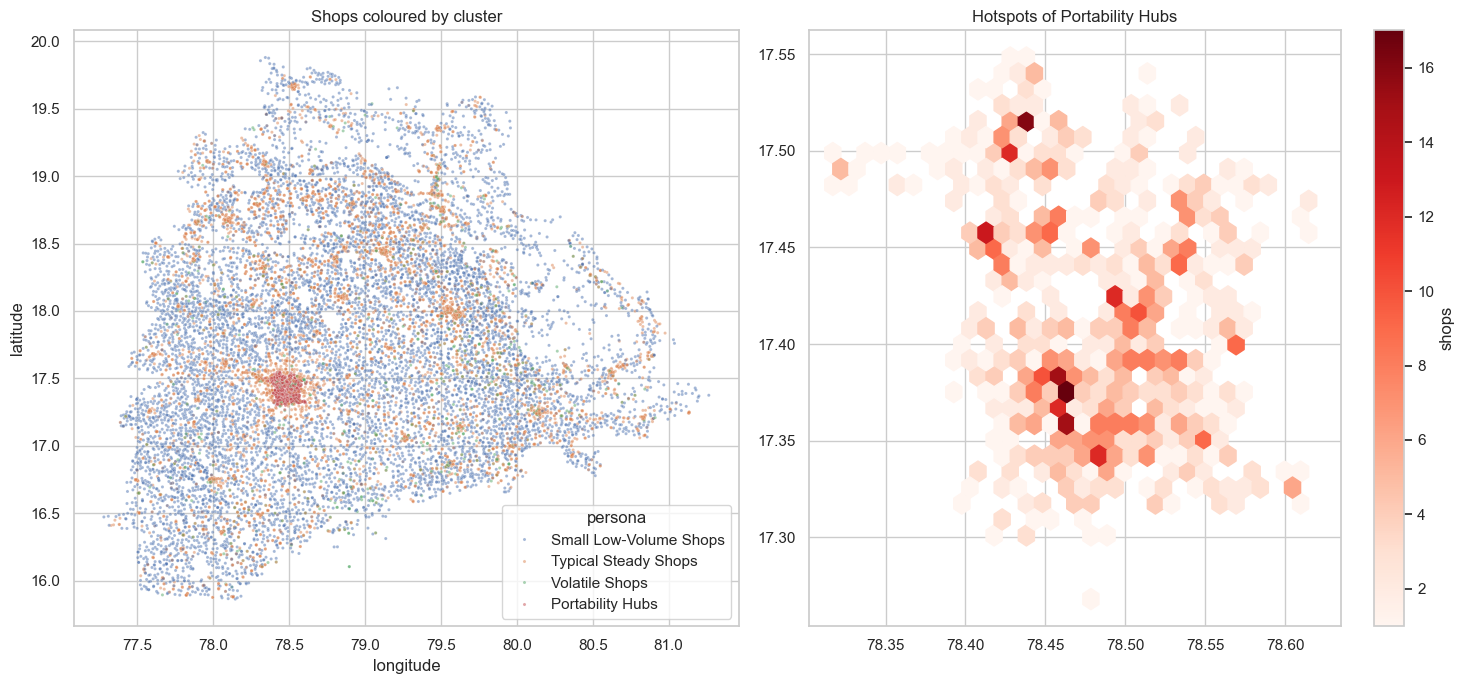

Shops without a correct GPS location (not drawn): 355


In [20]:
mapped = shop[shop["gps_ok"]]
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
sns.scatterplot(data=mapped, x="longitude", y="latitude", hue="persona", s=5, alpha=0.5, ax=ax[0])
ax[0].set_title("Shops coloured by cluster")
hubs = mapped[mapped["persona"] == "Portability Hubs"]
hb = ax[1].hexbin(hubs["longitude"], hubs["latitude"], gridsize=30, cmap="Reds", mincnt=1)
plt.colorbar(hb, ax=ax[1], label="shops")
ax[1].set_title("Hotspots of Portability Hubs")
plt.tight_layout()
plt.savefig("charts/geo_clusters_hotspots.png", dpi=120)
plt.show()
print("Shops without a correct GPS location (not drawn):", len(shop) - len(mapped))

**What I see:** the Portability Hubs are packed around Hyderabad (97% of the mapped Hyderabad shops, 63% in Medchal and 18% in Ranga Reddy), while the Small Low-Volume Shops are spread over the rural districts. Of the 182 DBSCAN noise shops with a GPS location, 84 (46%) are in Medchal, Ranga Reddy or Hyderabad and the rest are scattered over the state.

## Step 12 - Saving the files for the dashboard

In [21]:
keep = ["distCode", "shopNo", "distName", "officeName", "district_type", "latitude", "longitude", "gps_ok", "cluster", "persona",
        "is_noise", "util_z", "review_priority", "PC1", "PC2"] + FEATURES
shop.reset_index()[keep].round(4).to_csv("data/processed/shop_clusters.csv", index=False)

# one row per shop and year (for the year filter in the dashboard)
per_year = master.groupby(["distCode", "shopNo", "year"]).agg(
    avg_cards=("totalRcs", "mean"), avg_transactions=("noOfTrans", "mean"), total_trans=("noOfTrans", "sum"),
    total_cards=("totalRcs", "sum"), total_other=("otherShopTransCnt", "sum")).reset_index()
per_year["utilization_ratio"] = per_year["total_trans"] / per_year["total_cards"]
per_year["portability_share"] = per_year["total_other"] / per_year["total_trans"]
per_year[["distCode", "shopNo", "year", "avg_cards", "avg_transactions", "utilization_ratio", "portability_share"]].round(4).to_csv(
    "data/processed/shop_year_metrics.csv", index=False)

# portability per district and month (for the chart in the dashboard)
district_month = master.groupby(["distName", "date"])[["noOfTrans", "otherShopTransCnt"]].sum().reset_index()
district_month.to_csv("data/processed/district_monthly.csv", index=False)

profile.round(4).to_csv("reports/cluster_profile.csv")
shop.reset_index()[shop.reset_index()["review_priority"] != "Normal"][keep].sort_values("util_z", key=abs, ascending=False).round(3).to_csv(
    "reports/shops_to_review.csv", index=False)
print("Saved.")

Saved.


## Conclusion
* The three datasets were joined (99.97% of the transaction rows matched) and the EDA answered the questions in the project brief: portability is growing, cards and transactions are strongly linked, wheat is rare, and there is almost no seasonality.
* Using 5 chosen and scaled features, K-Means found 4 shop personas (silhouette 0.31) and DBSCAN found 185 unusual shops.
* The clusters are useful for the three business cases: policy (portability grows everywhere), fraud (a short review list) and logistics (hubs in the Hyderabad area).
* Limits: the silhouette score is modest, the urban/rural label is my own assumption, and there is no fraud label to check the flags against.